# Group Homework 3 · The GoMart report makeover
**Data Visualization · UEH · Session 3** · team notebook

| | |
|---|---|
| **Team** | *team name* · **team number** (from the LMS list): __ |
| **Status** | Formative: written feedback with the rubric in the brief. Task 0 is the first version of Module M3 of your project |
| **Submit** | File ▸ Download ▸ .ipynb as `GH3_TeamName.ipynb` + the evidence folder of Task 4, within 7 days on the LMS |

Read the brief *Group Homework 3* first. All GoMart data is simulated.

## Task 5 · One-page summary for the operations director (write this last)
**Big Idea:** *one complete sentence.*

*At most 100 words. The one-page figure is made in the last code cell of the notebook (it needs everything above);
after "Restart and run all", paste its image here.*

## Task 0 · Project: house style v0 and makeover plan (Module M3)
**Allocated project:** P__ · *title*

1. Put your `house_style.py` v0 in the cell below (palette in fixed order, sequential map, diverging map, fonts, number format).
2. Show the evidence: a swatch of your palette in colour, in greyscale and with simulated deuteranopia.
3. Makeover plan for one published chart from your domain: link, screenshot, critique table, photo of your hand sketch.

In [ ]:
# Task 0 · house_style.py v0 for your project (paste the file content here, then run it)
# PROJECT_PALETTE = [...]       # fixed order, one colour per category of your project
# SEQ_CMAP = "..."; DIV_CMAP = "..."
# def use_house_style(): ...

In [ ]:
# Task 0 · evidence: palette swatch in colour, greyscale, deuteranopia
# (use fig_to_rgb, to_grey and simulate_cvd from the Setup section below)

**Makeover plan.** Source (link, date accessed): ...

| # | What I see | Principle broken (name it) | Effect on the reader | My fix |
|---|---|---|---|---|
| 1 | | | | |
| 2 | | | | |
| 3 | | | | |
| 4 | | | | |

*Insert the photo of your hand sketch here.*

## Setup
Upload `gomart_orders_2025_clean.csv`, `gomart_districts.csv` and `gomart_targets_2025.csv`.
Run `gomart_bad_report.py` once (or open `gomart_bad_report.pdf`) to see the six charts you will audit.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.colors import TwoSlopeNorm, to_rgb

GREY, LIGHT, DARK, BLUE, ORANGE = "#a3a29c", "#d9d8d3", "#52514e", "#2a78d6", "#eb6834"
ZONE_COLOR = {"Central": "#a9c9ef", "Inner": "#5b9be3", "Outer": "#1f4f8f"}   # ordered: light -> dark

In [ ]:
orders = pd.read_csv("gomart_orders_2025_clean.csv", parse_dates=["order_time"])
districts = pd.read_csv("gomart_districts.csv")
targets = pd.read_csv("gomart_targets_2025.csv")
orders = orders.merge(districts, on="district", how="left", validate="many_to_one")
orders["month"] = orders["order_time"].dt.strftime("%Y-%m")
days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
orders["weekday"] = pd.Categorical(orders["order_time"].dt.strftime("%a"), categories=days, ordered=True)
orders["hour"] = orders["order_time"].dt.hour
tiers = ["none", "Silver", "Gold", "Platinum"]
orders["member_tier"] = pd.Categorical(orders["member_tier"], categories=tiers, ordered=True)
delivered = orders[orders["status"] == "delivered"]
print(orders.shape, "| orders without zone:", orders["zone"].isna().sum())

Helper functions from Tutorial 3 (given):

In [ ]:
def fig_to_rgb(fig):
    fig.canvas.draw()
    return np.asarray(fig.canvas.buffer_rgba())[..., :3] / 255

def to_grey(rgb):
    return np.asarray(rgb)[..., :3] @ np.array([0.299, 0.587, 0.114])

DEUTAN = np.array([[0.367322, 0.860646, -0.227968], [0.280085, 0.672501, 0.047413],
                   [-0.011820, 0.042940, 0.968881]])

def simulate_cvd(rgb, M=DEUTAN):
    lin = np.where(rgb <= 0.04045, rgb / 12.92, ((rgb + 0.055) / 1.055) ** 2.4)
    sim = np.clip(lin @ M.T, 0, 1)
    return np.where(sim <= 0.0031308, 12.92 * sim, 1.055 * sim ** (1 / 2.4) - 0.055)

## Task 1 · Audit the report
For each of the six charts: the task the chart should support (action + target), then at least four problems.

| Chart | Task it should support | Problem | Principle (name it) | Effect on the reader |
|---|---|---|---|---|
| 1 Orders by district | Compare the number of orders across the 10 districts and rank them (action: compare + rank; target: districts) | A pie with 10 slices of near-equal size (7.1% to 12.8%) | Effectiveness / expressiveness: angle and area are judged less accurately than position on a common scale (Cleveland & McGill) | The reader cannot tell whether Binh Thanh or Tan Binh is larger, and cannot see that the biggest district has 1.8 times the orders of the smallest |
| 1 | | The 10 slices use the `jet` rainbow and a separate 10-entry legend, and the slice labels repeat the legend | Colour job and short-term memory: ten colour-name pairs exceed the 4 to 7 items that working memory holds; colour carries no information because the district name is already the label | The reader jumps between legend and pie, and still loses track of which slice is which |
| 1 | | Slices are in alphabetical order (`sort_index`), not in order of size | Ordering: an ordered quantity needs an ordered layout; alphabetical order has no link to the task | The ranking, which is the point of the chart, is hidden; the reader has to sort ten percentages in their head |
| 1 | | `explode`, `shadow` and two-decimal percentages (`12.75%`) on every slice | Data-ink: decoration and false precision add ink that carries no information | The eye is pulled to the shadows and gaps, not to the size differences; the numbers are hard to scan |
| 1 | | Rainbow colours turn into a non-monotonic grey ramp, and several neighbours collapse for deuteranopia | Greyscale and colour-vision deficiency: lightness of `jet` is not monotonic and red-green pairs merge | In a black-and-white print or for a colour-blind reader, many slices cannot be told apart even with the legend |
| 2 Payments | | | | |
| ... | | | | |

## Task 2 · Redesign
### Chart 1 · Orders by district
*Task:* compare the number of orders across the 10 districts and rank them.  *Why this chart:* a horizontal bar chart sorted by size puts every value on one common baseline (position, the most accurate channel), and the district names can sit next to the bars, so there is no legend.

*Choices:* zero baseline; sorted from largest to smallest; grey for the eight other districts and one highlight colour for the two largest; direct value labels (count and share); no gridlines, no frame, no legend; the title states the finding.

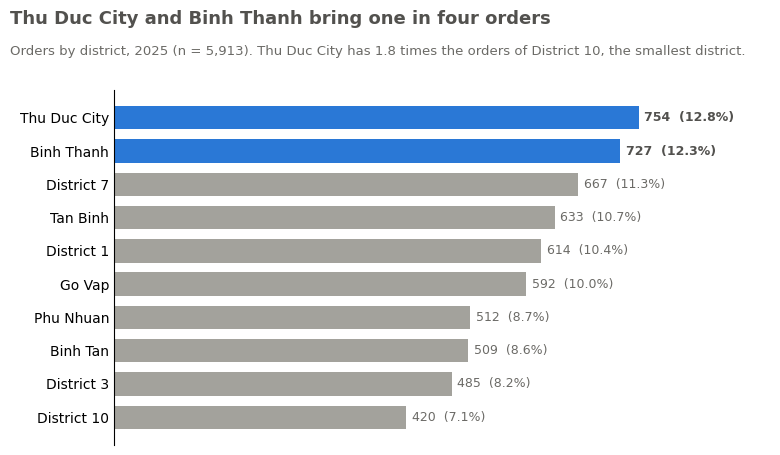

In [ ]:
# Chart 1 · Orders by district: sorted horizontal bars, grey + highlight
counts = orders["district"].value_counts()                  # already sorted, largest first
share = counts / counts.sum() * 100
top2 = counts.index[:2]
top2_share = counts[top2].sum() / counts.sum() * 100
ratio = counts.iloc[0] / counts.iloc[-1]

fig, ax = plt.subplots(figsize=(8, 5))
colors = [BLUE if d in top2 else GREY for d in counts.index]
bars = ax.barh(counts.index, counts.values, color=colors, height=0.7)
ax.invert_yaxis()                                           # largest at the top
for b, d in zip(bars, counts.index):
    ax.text(b.get_width() + 8, b.get_y() + b.get_height() / 2,
            f"{counts[d]:,}  ({share[d]:.1f}%)", va="center", fontsize=9,
            color=DARK if d in top2 else "#6b6a66", fontweight="bold" if d in top2 else "normal")
ax.set_xlim(0, counts.max() * 1.25)
ax.set_xticks([])                                           # values are labelled directly
ax.spines[["top", "right", "bottom"]].set_visible(False)
ax.tick_params(axis="y", length=0)

fig.suptitle(f"{top2[0]} and {top2[1]} bring one in four orders",
             x=0.02, ha="left", fontsize=13, fontweight="bold", color=DARK)
fig.text(0.02, 0.89, f"Orders by district, 2025 (n = {counts.sum():,}). {top2[0]} has {ratio:.1f} times the orders of {counts.index[-1]}, the smallest district.",
         ha="left", fontsize=9.5, color="#6b6a66")
fig.subplots_adjust(top=0.82, left=0.15, right=0.97)
fig1 = fig                                                  # kept for the Task 3 test
plt.show()

In [ ]:
# Check: every number in the Chart 1 title and the evidence behind it
print(counts.to_frame("orders").assign(share_pct=share.round(2)))
print("Total orders:", counts.sum())
print(f"Top two ({top2[0]} + {top2[1]}): {counts[top2].sum()} orders = {top2_share:.2f}% of all  ->  title says 'one in four' (25%)")
print(f"Fewest: {counts.index[-1]} with {counts.iloc[-1]} orders ({share.iloc[-1]:.2f}%); the largest is {ratio:.2f} times larger")
assert round(top2_share) == 25 and counts.index[-1] == "District 10"

              orders  share_pct
district                       
Thu Duc City     754      12.75
Binh Thanh       727      12.29
District 7       667      11.28
Tan Binh         633      10.71
District 1       614      10.38
Go Vap           592      10.01
Phu Nhuan        512       8.66
Binh Tan         509       8.61
District 3       485       8.20
District 10      420       7.10
Total orders: 5913
Top two (Thu Duc City + Binh Thanh): 1481 orders = 25.05% of all  ->  title says 'one in four' (25%)
Fewest: District 10 with 420 orders (7.10%); the largest is 1.80 times larger


### Chart 2 · Payments
*Task:* ...  *Why this chart:* ...

In [ ]:
# TODO: write your code here

### Chart 3 · Delivery time
*Task:* ...  *Why this chart:* ...

In [ ]:
# TODO: write your code here

In [ ]:
# TODO: write your code here

### Chart 4 · Peak times
*Task:* ...  *Why this chart:* ...

In [ ]:
# TODO: write your code here

### Chart 5 · Targets
*Task:* ...  *Why this chart:* ...

In [ ]:
# TODO: write your code here

In [ ]:
# TODO: write your code here

### Chart 6 · Basket by tier
*Task:* ...  *Why this chart:* ...

In [ ]:
# TODO: write your code here

In [ ]:
# TODO: write your code here

*Check: every number in your six titles, with the output that proves it.*

## Task 3 · Test for every reader
Greyscale and deuteranopia versions of all six redesigns. Then: one change you made because of a test.

Chart 1 grey values: highlight 0.42, other bars 0.63, gap 0.21
Deuteranopia grey values of highlight / other: [0.4  0.63]


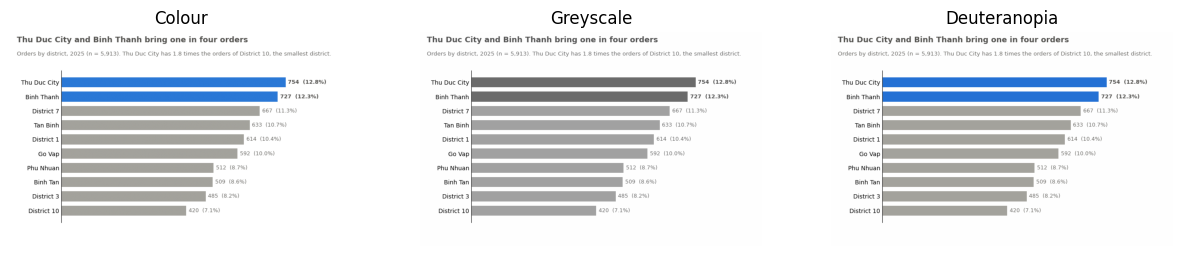

In [ ]:
# Task 3 · Chart 1 (Orders by district): colour, greyscale, deuteranopia
rgb = fig_to_rgb(fig1)
views = {"Colour": rgb, "Greyscale": np.dstack([to_grey(rgb)] * 3), "Deuteranopia": simulate_cvd(rgb)}
fig_t, axs = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, (name, img) in zip(axs, views.items()):
    ax.imshow(np.clip(img, 0, 1)); ax.set_title(name); ax.axis("off")
plt.show()
# lightness gap between the highlight and the grey bars (0 = same, 1 = black vs white)
g = lambda c: float(to_grey(np.array(to_rgb(c))))
print(f"Chart 1 grey values: highlight {g(BLUE):.2f}, other bars {g(GREY):.2f}, gap {g(GREY) - g(BLUE):.2f}")
sim = simulate_cvd(np.array([to_rgb(BLUE), to_rgb(GREY)]))
print("Deuteranopia grey values of highlight / other:", np.round(to_grey(sim), 2))
# TODO: the other five charts


*The change we made because of a test, and why:*

**Chart 1 (Orders by district):** passed both tests without a change. In greyscale the highlighted bars (grey value 0.42) are clearly darker than the other bars (0.63), and under deuteranopia the values stay 0.40 and 0.63, so the highlight does not rely on hue. This works because the design encodes "the two largest" with lightness plus position (sorted order) and direct labels, not with colour alone. The intern pie failed the same test: `jet` has a non-monotonic lightness and ten hues that merge.


## Task 4 · Perception experiment
### 4.1 Your stimulus sheet
Use **your team number** from the LMS list. Print the sheet (or put it in a form). Do not show the true values to anyone.

In [ ]:
def make_stimuli(team_number, path="stimulus_sheet.png"):
    """Perception experiment: one sheet with three panels (bars, pie, bubbles).
    Each panel shows five values A-E; the largest is marked with *. Values differ per panel
    and per team, so every team has its own experiment. Returns the true values (keep them secret)."""
    rng = np.random.default_rng(1000 + team_number)
    truth = {}
    fig, axs = plt.subplots(1, 3, figsize=(13, 4.2))
    for ax, kind in zip(axs, ["bars", "pie", "bubbles"]):
        v = np.round(rng.uniform(10, 90, 5))
        v[rng.integers(5)] = 100                                  # the reference value (only one)
        labels = [L + ("*" if val == 100 else "") for L, val in zip("ABCDE", v)]
        truth[kind] = dict(zip("ABCDE", v.astype(int).tolist()))
        if kind == "bars":
            ax.bar(labels, v, color="white", edgecolor="black")
            ax.set_yticks([]); ax.spines[["top", "right", "left"]].set_visible(False)
        elif kind == "pie":
            ax.pie(v, labels=labels, colors=["white"] * 5, wedgeprops=dict(edgecolor="black"),
                   startangle=90, counterclock=False)
        else:
            ax.scatter(range(5), [0] * 5, s=v / 100 * 2500, color="white", edgecolor="black")
            for i, L in enumerate(labels):
                ax.text(i, -0.55, L, ha="center")
            ax.set_ylim(-0.8, 0.8); ax.set_xlim(-0.7, 4.7); ax.axis("off")
        ax.set_title(f"Panel {['bars', 'pie', 'bubbles'].index(kind) + 1}")
    fig.text(0.5, 0.0, "The value marked * is 100. Estimate the other four values in each panel. "
             "Do not measure; answer within 30 seconds per panel.", ha="center", fontsize=10)
    fig.savefig(path, dpi=200, bbox_inches="tight")
    plt.close(fig)
    return truth

In [ ]:
# Make the stimulus sheet for team 10. The true values stay in `truth`; they are not printed.
truth = make_stimuli(team_number=10)
print("Sheet saved as stimulus_sheet.png;", {k: len(v) for k, v in truth.items()}, "values per panel")

Sheet saved as stimulus_sheet.png; {'bars': 5, 'pie': 5, 'bubbles': 5} values per panel


### 4.2 Protocol (fill in before you collect)
- **Who:** people who do not take this course; each member collects at least 3 respondents and is recorded as `collector`. Respondents are coded R01, R02, ...; no names are recorded. *(Collector tuan-anh: R01-R03. Confirm that all three are outside the course.)*
- **How:** each respondent receives the same file `stimulus_sheet.png` privately (not in a group chat), so no one sees another person's answers.
- **Task:** estimate by eye the four unmarked values in each panel, taking the value marked \* as 100. In the pie panel the question is "how large is this slice compared with the slice marked \*", not a percentage of the whole pie. About 30 seconds per panel; no ruler.
- **No help:** the same wording for everyone; no hints, no true values, no comments on the answers.
- **Recording:** one answer per item, typed in the format `Panel 1: A=__ B=__ D=__ E=__`; a screenshot of each reply (name hidden, time visible) goes to `evidence/`. An answer given as a range is recorded as its middle; "about half" is recorded as 50.
- **Consent:** the purpose and the "no name" rule were stated before the respondent answered.

### 4.3 Your answers
Save your answers as `experiment_answers.csv` with the columns
`respondent, encoding, item, true, judged, collector` (one row per estimate; `collector` = the student ID of the team
member who collected it). Upload it next to the notebook.

In [ ]:
# answers = pd.read_csv("experiment_answers.csv")
# answers["log_error"] = np.log2(np.abs(answers["judged"] - answers["true"]) + 1 / 8)   # Cleveland & McGill (1984)
# print(answers.groupby("encoding")["log_error"].agg(["mean", "count"]).round(2))

In [ ]:
# Task 4.3: log_error for our own answers, summarised by encoding
answers = pd.read_csv("experiment_answers.csv")
answers["log_error"] = np.log2(np.abs(answers["judged"] - answers["true"]) + 1 / 8)
answers["abs_error"] = (answers["judged"] - answers["true"]).abs()
print("Respondents:", answers["respondent"].nunique(), "| estimates:", len(answers),
      "| collectors:", answers["collector"].unique().tolist())
summary = answers.groupby("encoding").agg(mean_log_error=("log_error", "mean"),
                                          mean_abs_error=("abs_error", "mean"), n=("log_error", "count")).round(2)
print(summary)

# 95% bootstrap interval over respondents (resample respondents, then average their errors)
rng = np.random.default_rng(0)
per_resp = answers.groupby(["encoding", "respondent"])["log_error"].mean().unstack()   # encoding x respondent
ci = {}
for enc in per_resp.index:
    vals = per_resp.loc[enc].dropna().to_numpy()
    boots = [rng.choice(vals, size=len(vals), replace=True).mean() for _ in range(5000)]
    ci[enc] = np.percentile(boots, [2.5, 97.5])
print({k: np.round(v, 2).tolist() for k, v in ci.items()})

Respondents: 3 | estimates: 36 | collectors: ['tuan-anh']
          mean_log_error  mean_abs_error   n
encoding                                    
bars                1.05            2.25  12
bubbles             1.97           11.33  12
pie                 2.35            6.83  12
{'bars': [0.86, 1.29], 'bubbles': [-0.02, 4.33], 'pie': [1.18, 3.21]}


### 4.4 Result chart

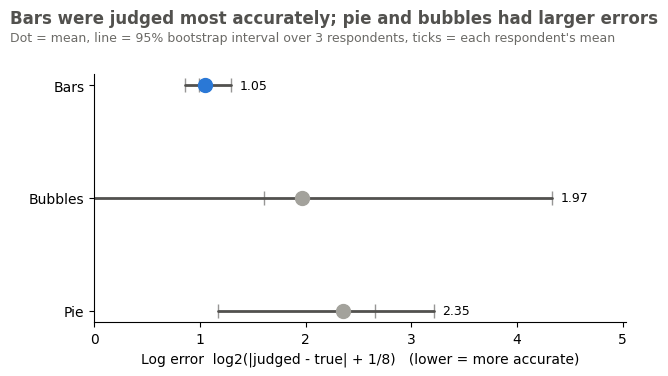

In [ ]:
# 4.4 Result chart: mean log error by encoding, 95% bootstrap interval over respondents
order = summary["mean_log_error"].sort_values().index.tolist()          # best (lowest error) first
fig, ax = plt.subplots(figsize=(7, 3.6))
for i, enc in enumerate(order):
    m = summary.loc[enc, "mean_log_error"]
    ax.plot(ci[enc], [i, i], color=DARK, lw=2, solid_capstyle="round")
    ax.plot(m, i, "o", color=BLUE if enc == order[0] else GREY, ms=10, zorder=3)
    ax.plot(per_resp.loc[enc].dropna(), [i] * per_resp.loc[enc].notna().sum(), "|", color=DARK, ms=10, alpha=.6)
    ax.text(ci[enc][1] + 0.08, i, f"{m:.2f}", va="center", fontsize=9)
ax.set_yticks(range(len(order)), [e.capitalize() for e in order]); ax.invert_yaxis()
ax.set_xlim(0, max(v[1] for v in ci.values()) + 0.7)
ax.set_xlabel("Log error  log2(|judged - true| + 1/8)   (lower = more accurate)")
ax.spines[["top", "right"]].set_visible(False)
n_resp = answers["respondent"].nunique()
fig.suptitle(f"Bars were judged most accurately; pie and bubbles had larger errors", x=0.02, ha="left", fontweight="bold", color=DARK)
fig.text(0.02, 0.89, f"Dot = mean, line = 95% bootstrap interval over {n_resp} respondents, ticks = each respondent's mean",
         fontsize=9, color="#6b6a66")
fig.subplots_adjust(top=0.8, left=0.14)
plt.show()

### 4.5 Interpretation (at most 150 words)
Our result agrees with Cleveland & McGill (1984) in direction: bars had the lowest mean log error (1.05), then bubbles (1.97) and pie (2.35). In points, the mean absolute error was 2.2 for bars, 6.8 for pie and 11.3 for bubbles. The bubble panel was hardest: R01 judged C, D and E as 50, 30 and 40 where the true values were 89, 65 and 78, an error of about 40 points, while R02 and R03 were close. Pie slices were off by a few points but never exact, which the log measure punishes. Bars were easiest; D was almost exact.

**Limitations.** (1) Only 3 respondents (36 estimates), so the bootstrap intervals are wide and overlap (bubbles: -0.02 to 4.33); this is a first signal, not proof. (2) The respondents are not a random sample, saw the sheet on screens of different sizes, and saw the panels in the same order, so practice or fatigue may affect the last panel.

## Task 5 · The one-page figure
Three panels, one action title, consistent colours with Tasks 2-3.

In [ ]:
# Task 5: one figure, three panels, one action title
# TODO: write your code here

## Task 6 · Team and AI
| Member | What they did | Answers collected (Task 4) | Share of work |
|---|---|---|---|
| | | | |

In [ ]:
AI_USE = """
Tool(s) used:
What we asked:
What we checked or changed ourselves:
"""
print(AI_USE)